In [96]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn 
import os

In [97]:
# Reading in the listing file first to do some really basis EDA
listings_df = pd.read_csv('./data/listings.csv')
listings_df.head(5)

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,71609,https://www.airbnb.com/rooms/71609,20260629151954,2026-07-02,previous scrape,Ensuite Room (Room 1 & 2) near EXPO,For 3 rooms.Book room 1&2 and room 4,NaN,https://a0.muscache.com/pictures/24453191/3580...,367042,...,4.78,4.26,4.32,NaN,NaN,5,0,5,0,0.11
1,71896,https://www.airbnb.com/rooms/71896,20260629151954,2026-07-02,previous scrape,B&B Room 1 near Airport & EXPO,NaN,NaN,https://a0.muscache.com/pictures/2440674/ac4f4...,367042,...,4.43,4.17,4.04,NaN,NaN,5,0,5,0,0.13
2,71903,https://www.airbnb.com/rooms/71903,20260629151954,2026-07-02,previous scrape,Room 2-near Airport & EXPO,"Like your own home, 24hrs access.",NaN,https://a0.muscache.com/pictures/568743/7bc623...,367042,...,4.64,4.50,4.36,NaN,NaN,5,0,5,0,0.25
3,294281,https://www.airbnb.com/rooms/294281,20260629151954,2026-07-02,previous scrape,5 mins walk from Newton subway,I have 3 bedrooms in a charming British style...,NaN,https://a0.muscache.com/pictures/4607862/87f42...,1521514,...,4.66,4.52,4.39,NaN,NaN,7,1,6,0,0.75
4,344803,https://www.airbnb.com/rooms/344803,20260629151954,2026-07-02,previous scrape,Budget short stay room near EXPO,Direct bus 24 from airport to this place.Walki...,NaN,https://a0.muscache.com/pictures/4240c88e-4dc2...,367042,...,4.58,4.66,4.44,NaN,NaN,5,0,5,0,0.34


In [98]:
# Let us inspect the size of the listings dataset
print(listings_df.shape)

print(listings_df.isnull().sum())

(3097, 90)
id                                                 0
listing_url                                        0
scrape_id                                          0
last_scraped                                       0
source                                             0
                                                ... 
calculated_host_listings_count                     0
calculated_host_listings_count_entire_homes        0
calculated_host_listings_count_private_rooms       0
calculated_host_listings_count_shared_rooms        0
reviews_per_month                               1361
Length: 90, dtype: int64


In [99]:
# 2. Same, but with a % so it's easier to judge (top 20 only)
pct = (listings_df.isnull().mean() * 100).round(1)
print(pct[pct > 0].sort_values(ascending=False).head(30))
print(f"{(pct > 0).sum()} of {listings_df.shape[1]} columns have missing values")



neighbourhood                  100.0
neighborhood_overview          100.0
host_total_listings_count      100.0
host_neighbourhood             100.0
host_thumbnail_url             100.0
calendar_updated               100.0
host_acceptance_rate           100.0
host_response_rate             100.0
host_response_time             100.0
host_verifications             100.0
host_since                     100.0
instant_bookable               100.0
bathrooms                       62.8
beds                            58.3
review_scores_location          44.0
review_scores_value             44.0
review_scores_rating            43.9
review_scores_accuracy          43.9
first_review                    43.9
review_scores_cleanliness       43.9
review_scores_checkin           43.9
review_scores_communication     43.9
last_review                     43.9
reviews_per_month               43.9
license                         43.8
host_location                   37.3
bedrooms                        36.8
h

We can see that there are alot of missing values (52/91), so we really need to be careful in dealing wih them.

### Median price by neighbourhood
`price` is a string (e.g. `$31.71`), so it is converted to a number first. Neighbourhoods with only one listing are excluded, as a single listing's price isn't a meaningful median. Listings with a missing price (~16%) are ignored.

Dropped 1 single-property neighbourhood(s)


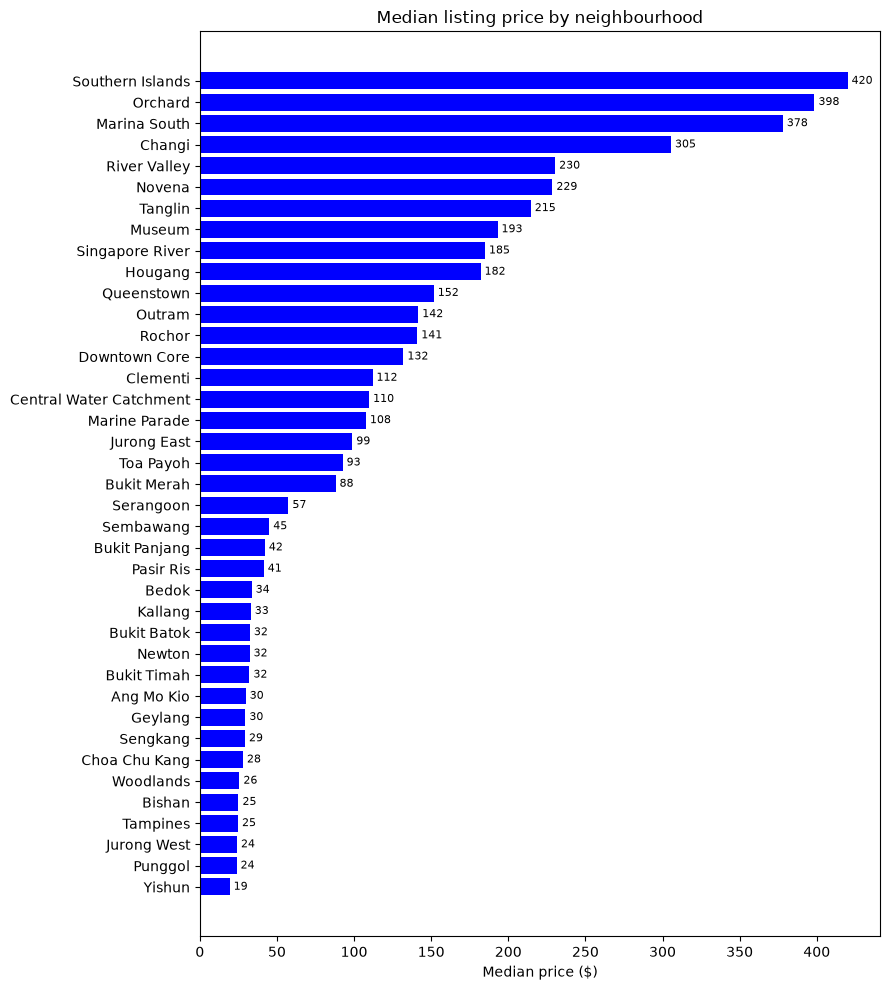

In [100]:
# Median price per neighbourhood, excluding neighbourhoods with only 1 listing
# price is stored as a string like '$31.71', so clean it into a float first
price = listings_df['price'].astype(str).str.replace(r'[$,]', '', regex=True)
listings_df['price_num'] = pd.to_numeric(price, errors='coerce')

# Count listings per neighbourhood (all listings), keep only those with > 1
counts = listings_df['neighbourhood_cleansed'].value_counts()
multi = counts[counts > 1].index
print(f"Dropped {(counts == 1).sum()} single-property neighbourhood(s)")

price_df = listings_df[listings_df['neighbourhood_cleansed'].isin(multi)].dropna(subset=['price_num'])

median_price = (price_df.groupby('neighbourhood_cleansed')['price_num']
                .median()
                .sort_values())

fig, ax = plt.subplots(figsize=(9, 10))
ax.barh(median_price.index, median_price.values, color='blue')
ax.set_xlabel('Median price ($)')
ax.set_ylabel('')
ax.set_title('Median listing price by neighbourhood')
for y, v in enumerate(median_price.values):
    ax.text(v, y, f' {v:.0f}', va='center', fontsize=8)
plt.tight_layout()
plt.show()

As expected, apartments in the touristy neighbourhoods such as `Orchard`, `Southern Islands`, `Marina South` and `Changi` are those with the highest median listing prices.

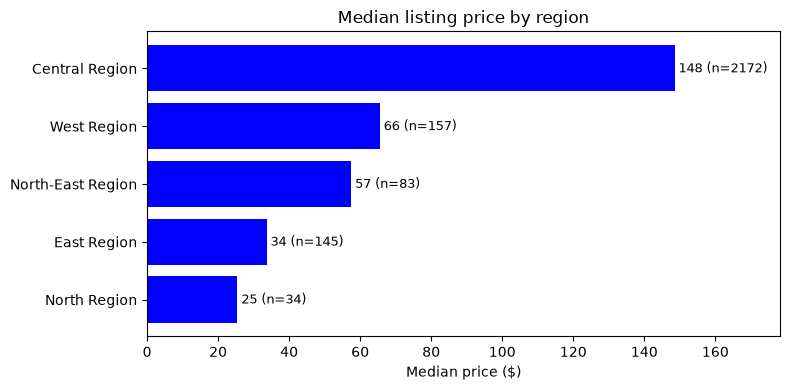

In [101]:
# Median price per region (neighbourhood_group_cleansed), same filtered data as above
region_stats = (price_df.groupby('neighbourhood_group_cleansed')['price_num']
                .agg(median='median', n='count')
                .sort_values('median'))

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(region_stats.index, region_stats['median'], color='blue')
ax.set_xlabel('Median price ($)')
ax.set_ylabel('')
ax.set_title('Median listing price by region')
for y, (m, n) in enumerate(zip(region_stats['median'], region_stats['n'])):
    ax.text(m, y, f' {m:.0f} (n={n})', va='center', fontsize=9)
ax.set_xlim(0, region_stats['median'].max() * 1.2)
plt.tight_layout()
plt.show()

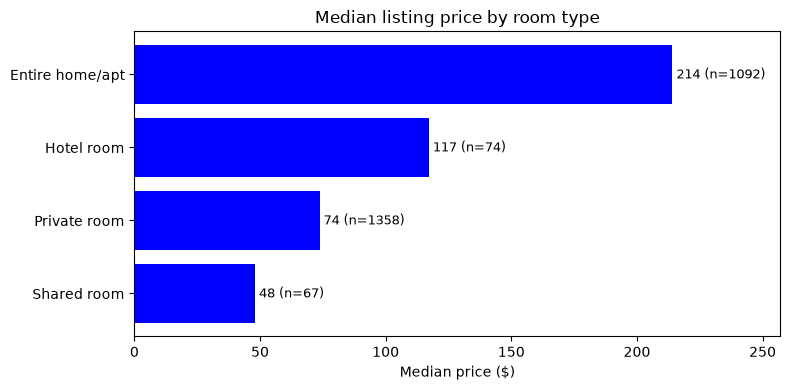

In [102]:
# Median price per room type, same filtered data as above
room_stats = (price_df.groupby('room_type')['price_num']
              .agg(median='median', n='count')
              .sort_values('median'))

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(room_stats.index, room_stats['median'], color='blue')
ax.set_xlabel('Median price ($)')
ax.set_ylabel('')
ax.set_title('Median listing price by room type')
for y, (m, n) in enumerate(zip(room_stats['median'], room_stats['n'])):
    ax.text(m, y, f' {m:.0f} (n={n})', va='center', fontsize=9)
ax.set_xlim(0, room_stats['median'].max() * 1.2)
plt.tight_layout()
plt.show()

Okay - again as expected, renting an entire home/apartment ot staying in an hotel room is definitely pricier that renting a personal private room and shared room.

room_type                     Entire home/apt  Hotel room  Private room  \
neighbourhood_group_cleansed                                              
Central Region                          951.0        74.0        1081.0   
East Region                              31.0         NaN         113.0   
North Region                              4.0         NaN          30.0   
North-East Region                        31.0         NaN          52.0   
West Region                              75.0         NaN          82.0   

room_type                     Shared room  
neighbourhood_group_cleansed               
Central Region                       66.0  
East Region                           1.0  
North Region                          NaN  
North-East Region                     NaN  
West Region                           NaN  


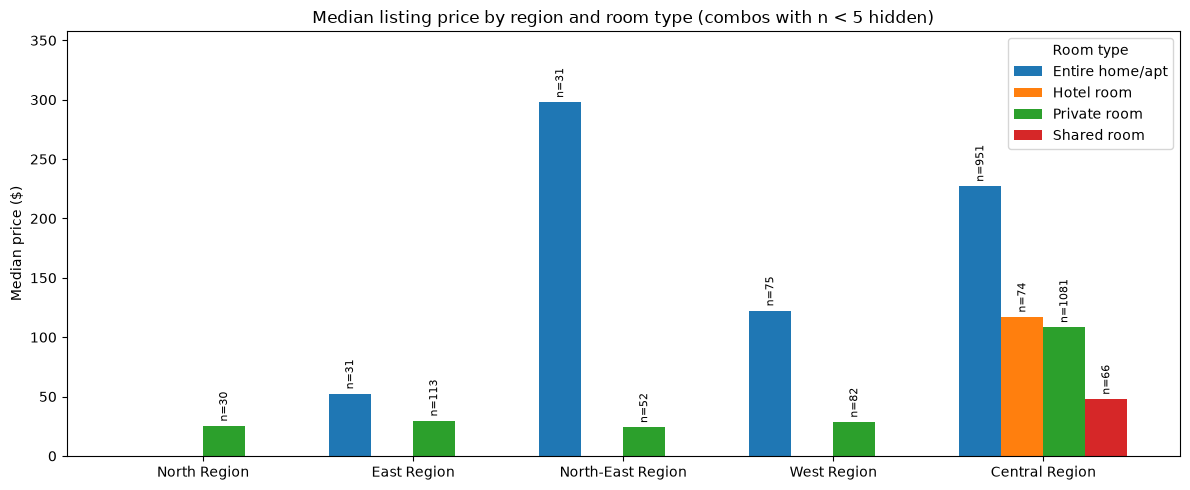

In [103]:
# Median price by region AND room type (grouped bars)
MIN_N = 5  # hide region/room type combos with fewer priced listings than this

combo = (price_df.groupby(['neighbourhood_group_cleansed', 'room_type'])['price_num']
         .agg(median='median', n='count')
         .reset_index())
n_all = combo.pivot(index='neighbourhood_group_cleansed', columns='room_type', values='n')
print(n_all)  # listing counts for every combo, including hidden ones

combo = combo[combo['n'] >= MIN_N]
pivot = combo.pivot(index='neighbourhood_group_cleansed', columns='room_type', values='median')
pivot = pivot.loc[region_stats.index]  # same region order as the region chart
n_pivot = n_all.loc[pivot.index, pivot.columns]

ax = pivot.plot(kind='bar', figsize=(12, 5), width=0.8)
ax.set_xlabel('')
ax.set_ylabel('Median price ($)')
ax.set_title(f'Median listing price by region and room type (combos with n < {MIN_N} hidden)')
ax.legend(title='Room type')

# label each bar with its listing count; containers follow the column order of pivot
for container, room in zip(ax.containers, pivot.columns):
    labels = [f'n={int(n_pivot.loc[region, room])}' if pd.notna(pivot.loc[region, room]) else ''
              for region in pivot.index]
    ax.bar_label(container, labels=labels, rotation=90, padding=3, fontsize=8)

ax.set_ylim(0, pivot.max().max() * 1.2)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

Alright, this is way more insightful..we can see that the median listing prices for renting an entire home/apartment and hotel room is definitely pricier than renting just a private room or shared room.

In addition, we can see that the central region has got the most offering types for consumers.

1736 of 3097 listings have a last_review date
Period covered: 2015-06 to 2026-06


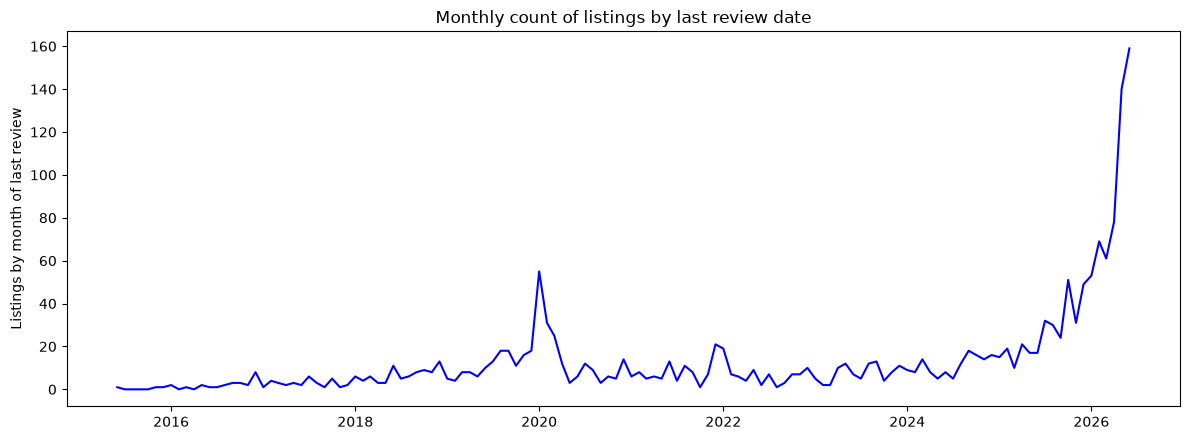

In [104]:
# Monthly trend using last_review as a proxy for rental activity
# (there is no calendar/reviews file, so this is the closest signal in listings.csv)
last_rev = pd.to_datetime(listings_df['last_review'], errors='coerce').dropna()
monthly = last_rev.dt.to_period('M').value_counts().sort_index()

# fill months with zero listings so gaps show up as gaps, not as straight lines
monthly = monthly.reindex(pd.period_range(monthly.index.min(), monthly.index.max(), freq='M'), fill_value=0)
print(f"{len(last_rev)} of {len(listings_df)} listings have a last_review date")
print(f"Period covered: {monthly.index.min()} to {monthly.index.max()}")

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(monthly.index.to_timestamp(), monthly.values, color='blue')
ax.set_xlabel('')
ax.set_ylabel('Listings by month of last review')
ax.set_title('Monthly count of listings by last review date')
plt.tight_layout()
plt.show()

Ok what do we see here?? It seems that number of listings stayed quite constant..till we see a surge from later part of 2025 to 2026..

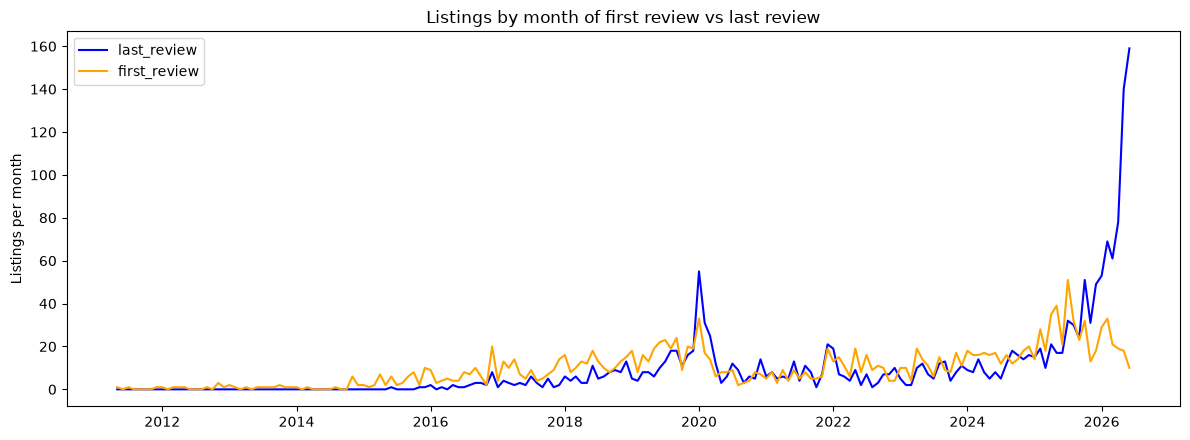

first_review
2019    210
2020    119
2021     86
2022    126
2023    134
2024    192
2025    324
2026    130
Name: count, dtype: int64


In [105]:
# Check 1: first_review vs last_review by month
# first_review is not affected by the "recent listings always have a recent last review" effect
first_rev = pd.to_datetime(listings_df['first_review'], errors='coerce').dropna()
all_months = pd.period_range(min(first_rev.min(), last_rev.min()).to_period('M'),
                             max(first_rev.max(), last_rev.max()).to_period('M'), freq='M')

first_m = first_rev.dt.to_period('M').value_counts().reindex(all_months, fill_value=0)
last_m = last_rev.dt.to_period('M').value_counts().reindex(all_months, fill_value=0)

fig, ax = plt.subplots(figsize=(12, 4.5))
ax.plot(all_months.to_timestamp(), last_m.values, color='blue', label='last_review')
ax.plot(all_months.to_timestamp(), first_m.values, color='orange', label='first_review')
ax.set_ylabel('Listings per month')
ax.set_title('Listings by month of first review vs last review')
ax.legend()
plt.tight_layout()
plt.show()

# yearly totals of new listings getting their first review
print(first_rev.dt.year.value_counts().sort_index().tail(8))

In [106]:
# Check 2: total reviews received in different windows (counts every review, not just the last one)
ltm = listings_df['number_of_reviews_ltm'].sum()   # last 12 months
ly = listings_df['number_of_reviews_ly'].sum()     # the 12 months before that
l30 = listings_df['number_of_reviews_l30d'].sum()  # last 30 days

print(f"Reviews in last 12 months:        {ltm:,.0f}  (~{ltm/12:,.0f} per month)")
print(f"Reviews in the 12 months before:  {ly:,.0f}")
print(f"Reviews in the last 30 days:      {l30:,.0f}")
print(f"Listings with a review in last 12 months: {(listings_df['number_of_reviews_ltm'] > 0).sum()} of {len(listings_df)}")

Reviews in last 12 months:        6,778  (~565 per month)
Reviews in the 12 months before:  6,738
Reviews in the last 30 days:      325
Listings with a review in last 12 months: 776 of 3097


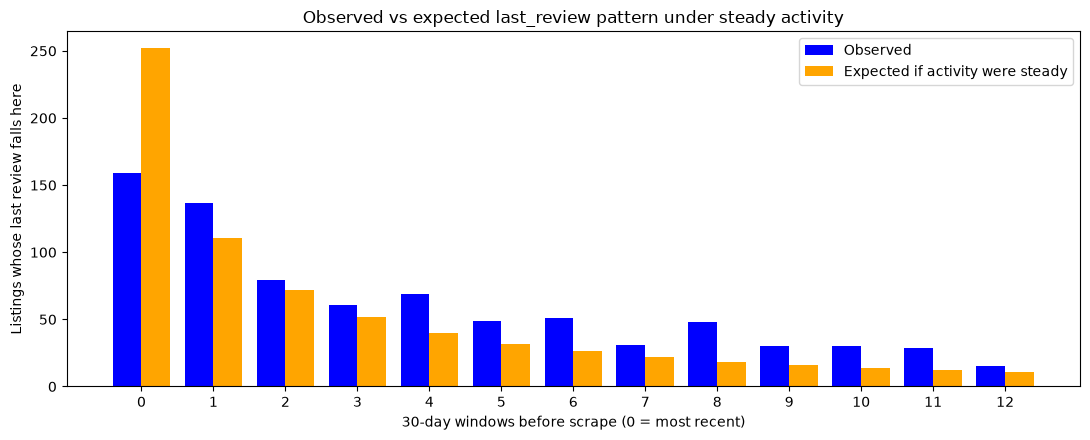

In [107]:
# Check 3: would a perfectly steady business still produce a late "surge" in last_review?
# For each listing, assume reviews arrive at a constant rate (number_of_reviews_ltm / 365 per day).
# The chance its last review falls in the k-th 30-day window before the scrape is then
# exp(-rate*30k) - exp(-rate*30(k+1)). Summing over listings gives the counts we'd expect
# from steady activity alone.
scrape_dt = pd.to_datetime(listings_df['last_scraped'])
days_ago = (scrape_dt - pd.to_datetime(listings_df['last_review'], errors='coerce')).dt.days.dropna()
observed = (days_ago // 30).astype(int).value_counts().reindex(range(13), fill_value=0)

rate = (listings_df['number_of_reviews_ltm'].fillna(0) / 365).values
rate = rate[rate > 0][:, None]               # only listings that were reviewed in the last 12 months
k = np.arange(13)[None, :]
expected = (np.exp(-rate * 30 * k) - np.exp(-rate * 30 * (k + 1))).sum(axis=0)

x = np.arange(13)
fig, ax = plt.subplots(figsize=(11, 4.5))
ax.bar(x - 0.2, observed.values, width=0.4, color='blue', label='Observed')
ax.bar(x + 0.2, expected, width=0.4, color='orange', label='Expected if activity were steady')
ax.set_xticks(x)
ax.set_xticklabels([f'{i}' for i in x])
ax.set_xlabel('30-day windows before scrape (0 = most recent)')
ax.set_ylabel('Listings whose last review falls here')
ax.set_title('Observed vs expected last_review pattern under steady activity')
ax.legend()
plt.tight_layout()
plt.show()

### Conclusion: is the late-2025 surge real?

Mostly no. The surge in the `last_review` chart is largely an artifact of how that column works. Each listing only has one `last_review` date, so any listing that is still active will always have a recent one. That piles counts into the latest months however busy those months really were.

The three checks above support this:

1. **First review vs last review:** `first_review` does not surge. New listings getting their first review stayed at roughly 18-33 per month through late 2025 and 2026. By year it rose from 192 (2024) to 324 (2025), which is real growth in 2025, but there is no late-2025 jump.
2. **Review totals:** reviews in the last 12 months (6,778) are about the same as the 12 months before (6,738). The last 30 days (325) are below the 12-month average of ~565 per month. Activity is flat, not accelerating.
3. **Steady-activity simulation:** if every listing received reviews at a constant rate, we would still expect a steep pile-up of last reviews in the most recent 30-day windows. The observed counts are no higher than that, so the surge needs no real increase in activity to explain it.

**Takeaway:** rental activity looks roughly flat over the last two years. The only feature that looks like a real event is the January 2020 bump (around the COVID period).

**Caveats:** only ~56% of listings have review dates, and reviews are only a proxy for stays (not every guest leaves one). Reviews also arrive in bursts, so the simulation matches the observed pattern approximately, not exactly. For a proper monthly rental trend we would need `calendar.csv` or `reviews.csv`.

## Spatial point pattern analysis

Each listing is treated as a point on the map of Singapore. We want to know where the points are densest (kernel density estimation) and whether they are clustered more than random scatter would be (K-function). First step: plot the listings over the neighbourhood boundaries to check that everything lines up.

In [108]:
import geopandas as gpd

boundaries = gpd.read_file('./data/neighbourhoods.geojson')

print(boundaries.head(5)) 

if boundaries.crs is None:
    boundaries = boundaries.set_crs(epsg=4326)

print(boundaries.head(5))

   neighbourhood neighbourhood_group  \
0      Pasir Ris         East Region   
1        Seletar   North-East Region   
2   Sungei Kadut        North Region   
3        Orchard      Central Region   
4  Downtown Core      Central Region   

                                            geometry  
0  MULTIPOLYGON (((103.95322 1.38202, 103.9535 1....  
1  MULTIPOLYGON (((103.88691 1.42649, 103.88812 1...  
2  MULTIPOLYGON (((103.7644 1.44345, 103.76443 1....  
3  MULTIPOLYGON (((103.84298 1.30001, 103.84294 1...  
4  MULTIPOLYGON (((103.85942 1.29978, 103.85954 1...  
   neighbourhood neighbourhood_group  \
0      Pasir Ris         East Region   
1        Seletar   North-East Region   
2   Sungei Kadut        North Region   
3        Orchard      Central Region   
4  Downtown Core      Central Region   

                                            geometry  
0  MULTIPOLYGON (((103.95322 1.38202, 103.9535 1....  
1  MULTIPOLYGON (((103.88691 1.42649, 103.88812 1...  
2  MULTIPOLYGON (((103.

In [109]:
listings_gdf = gpd.GeoDataFrame(
    listings_df,                                   # keep all the original columns
    geometry=gpd.points_from_xy(listings_df['longitude'], listings_df['latitude']),  # add the point shapes
    crs='EPSG:4326'                                # same lat/long system as the boundaries, so they match
)

listings_gdf.head(5)

,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month,price_num,geometry
0,71609,https://www.airbnb.com/rooms/71609,20260629151954,2026-07-02,previous scrape,Ensuite Room (Room 1 & 2) near EXPO,For 3 rooms.Book room 1&2 and room 4,NaN,https://a0.muscache.com/pictures/24453191/3580...,367042,...,4.32,NaN,NaN,5,0,5,0,0.11,NaN,POINT (103.95887 1.34537)
1,71896,https://www.airbnb.com/rooms/71896,20260629151954,2026-07-02,previous scrape,B&B Room 1 near Airport & EXPO,NaN,NaN,https://a0.muscache.com/pictures/2440674/ac4f4...,367042,...,4.04,NaN,NaN,5,0,5,0,0.13,NaN,POINT (103.95958 1.34754)
2,71903,https://www.airbnb.com/rooms/71903,20260629151954,2026-07-02,previous scrape,Room 2-near Airport & EXPO,"Like your own home, 24hrs access.",NaN,https://a0.muscache.com/pictures/568743/7bc623...,367042,...,4.36,NaN,NaN,5,0,5,0,0.25,NaN,POINT (103.961 1.34531)
3,294281,https://www.airbnb.com/rooms/294281,20260629151954,2026-07-02,previous scrape,5 mins walk from Newton subway,I have 3 bedrooms in a charming British style...,NaN,https://a0.muscache.com/pictures/4607862/87f42...,1521514,...,4.39,NaN,NaN,7,1,6,0,0.75,31.71,POINT (103.83924 1.31142)
4,344803,https://www.airbnb.com/rooms/344803,20260629151954,2026-07-02,previous scrape,Budget short stay room near EXPO,Direct bus 24 from airport to this place.Walki...,NaN,https://a0.muscache.com/pictures/4240c88e-4dc2...,367042,...,4.44,NaN,NaN,5,0,5,0,0.34,14.66,POINT (103.9609 1.34917)


55 boundary polygons, 3097 listings, 0 listings outside all polygons


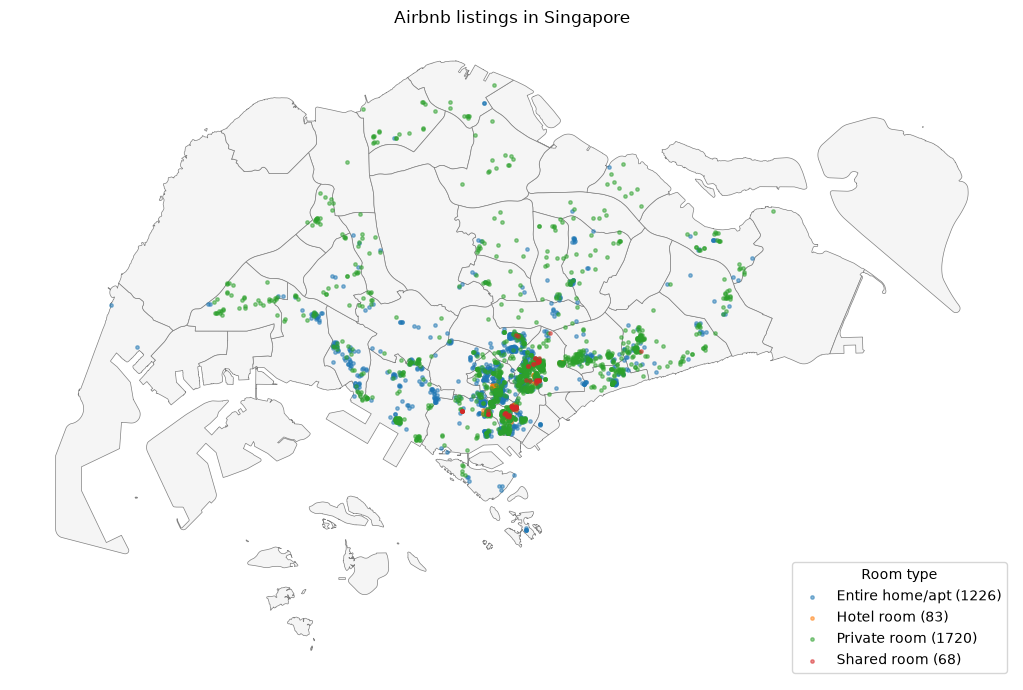

In [110]:
# geopandas = pandas + maps. It adds a 'geometry' column that holds shapes (points, polygons).
import geopandas as gpd

# ---------- STEP 1: load the boundary shapes ----------
# neighbourhoods.geojson holds one polygon (the outline) per neighbourhood.
# read_file gives a GeoDataFrame: like a normal DataFrame, plus a 'geometry' column with the outline.
boundaries = gpd.read_file('./data/neighbourhoods.geojson')

# CRS = coordinate reference system, i.e. the "language" the coordinates are written in.
# EPSG:4326 is plain latitude/longitude (what GPS uses). This file doesn't say which CRS it uses,
# so we tell geopandas to assume lat/long. Without a CRS, geopandas can't line up two layers.
if boundaries.crs is None:
    boundaries = boundaries.set_crs(epsg=4326)

# ---------- STEP 2: turn the listings into points on the map ----------
# Our listings are just a table with latitude and longitude columns.
# points_from_xy builds a map point from each pair. NOTE the order: x = longitude, y = latitude.
# (Mixing these up is the most common mistake in GIS and would put the points in the wrong place.)
listings_gdf = gpd.GeoDataFrame(
    listings_df,                                   # keep all the original columns
    geometry=gpd.points_from_xy(listings_df['longitude'], listings_df['latitude']),  # add the point shapes
    crs='EPSG:4326'                                # same lat/long system as the boundaries, so they match
)

# ---------- STEP 3: sanity check - do the points land inside the boundaries? ----------
# A "spatial join" (sjoin) matches rows by location instead of by a shared ID.
# Here: for each listing point, find the boundary polygon it sits "within".
# how='left' keeps every listing, even ones that match nothing (those get NaN in 'index_right').
inside = gpd.sjoin(listings_gdf, boundaries[['geometry']], how='left', predicate='within')
inside = inside[~inside.index.duplicated()]  # a point exactly on a shared edge can match two polygons, so drop repeats

# 'index_right' is the matched polygon's row number. NaN = the point is outside every polygon.
n_outside = inside['index_right'].isna().sum()
print(f"{len(boundaries)} boundary polygons, {len(listings_gdf)} listings, {n_outside} listings outside all polygons")

# ---------- STEP 4: draw the map ----------
fig, ax = plt.subplots(figsize=(12, 7))   # a blank canvas (fig) and one set of axes (ax) to draw on

# Draw the neighbourhood outlines first (the bottom layer): light grey fill, thin grey border.
boundaries.plot(ax=ax, color='whitesmoke', edgecolor='grey', linewidth=0.5)

# Then draw the listing points on top (the top layer), one colour per room type.
# groupby splits listings by room type; each loop gives the room type name and its rows (grp).
for room, grp in listings_gdf.groupby('room_type'):
    # markersize = dot size; alpha = transparency (0.5 = see-through, so overlapping dots look darker)
    grp.plot(ax=ax, markersize=6, alpha=0.5, label=f'{room} ({len(grp)})')

ax.legend(title='Room type', loc='lower right')  # colour key, with the number of listings per type
ax.set_title('Airbnb listings in Singapore')
ax.set_axis_off()       # hide the x/y axis numbers; on a map they're just lat/long values and add clutter
plt.tight_layout()
plt.show()

### Kernel density estimation (KDE)

The dot map is hard to read where listings overlap. KDE turns the dots into a smooth heatmap: every listing adds a small bump around itself, and where many bumps overlap the density is high. The colour shows roughly how many listings per square km there would be at each spot. The bump width (bandwidth) is a choice that changes how smooth the map looks, so it is worth trying a few values.

Approx. width of each bump (metres) in x and y: [324. 217.]


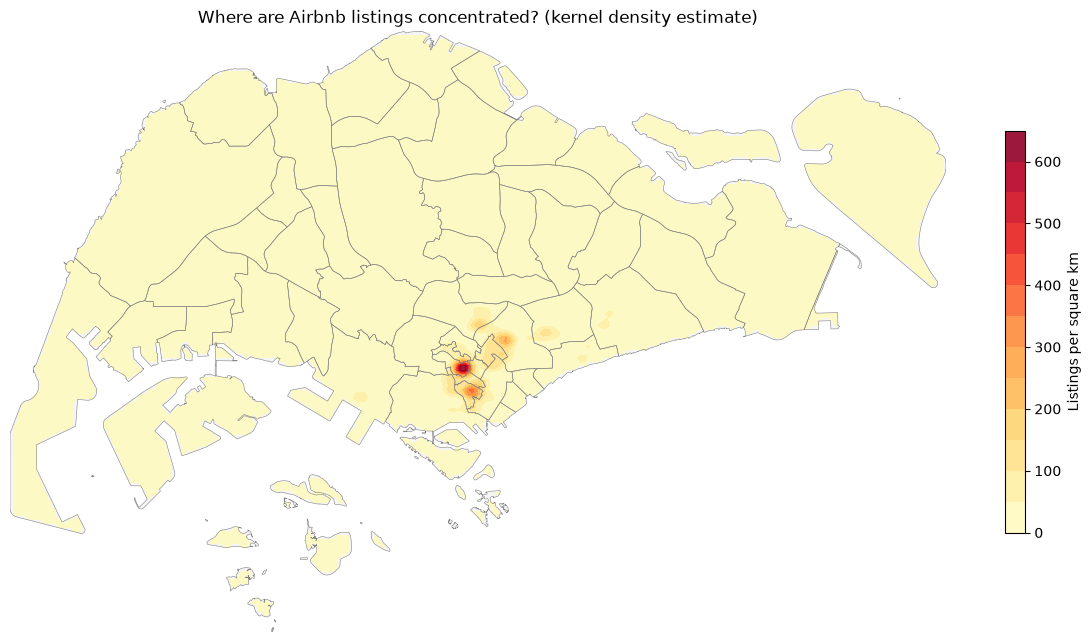

In [115]:
from scipy.stats import gaussian_kde
import shapely

# ---------- STEP 1: switch to a coordinate system measured in METRES ----------
# Lat/long are in degrees, and a degree is not a fixed distance, so it is a poor unit for "how close are two points".
# EPSG:3414 (SVY21) is Singapore's official local system, where x and y are in metres.
# to_crs converts both layers into it so that distances mean something.
listings_m = listings_gdf.to_crs(epsg=3414)
boundaries_m = boundaries.to_crs(epsg=3414)

# ---------- STEP 2: fit the KDE ----------
# Collect the x and y of every listing into one array with 2 rows (x row, y row) and one column per listing.
xy = np.vstack([listings_m.geometry.x, listings_m.geometry.y])

# gaussian_kde puts a small smooth "bump" on every listing; where many bumps overlap, density is high.
# bw_method (bandwidth) controls how wide each bump is:
#   smaller number = narrow bumps = detailed, spiky map;  bigger number = wide bumps = smooth, blurry map.
# 0.05 is a starting point. Try 0.03 or 0.1 and see how the map changes.
kde = gaussian_kde(xy, bw_method=0.07)
print("Approx. width of each bump (metres) in x and y:", np.sqrt(np.diag(kde.covariance)).round(0))

# ---------- STEP 3: evaluate the density on a grid of locations ----------
# KDE is a formula, so to draw it we ask it for the density at many evenly spaced locations (a grid) covering Singapore.
minx, miny, maxx, maxy = boundaries_m.total_bounds     # the box that just contains Singapore
gx = np.linspace(minx, maxx, 250)                      # 250 x positions across
gy = np.linspace(miny, maxy, 150)                      # 150 y positions up
XX, YY = np.meshgrid(gx, gy)                           # every (x, y) combination: the grid points
grid = np.vstack([XX.ravel(), YY.ravel()])             # flatten into the same 2-row layout as xy

density = kde(grid).reshape(XX.shape)                  # density at each grid point, back in grid shape

# The raw KDE values are tiny and hard to read. Multiply by the number of listings to get
# "expected listings per square metre", then by 1,000,000 to get "listings per square km".
density = density * len(listings_m) * 1_000_000

# ---------- STEP 4: blank out the sea ----------
# The KDE gives a value everywhere, including the water. Keep only grid points that fall on land.
# Some outlines in the geojson have tiny flaws (e.g. an edge that touches itself), which breaks
# GEOS operations like merging all polygons into one. make_valid() repairs those flaws first.
valid_shapes = boundaries_m.geometry.make_valid()

# For each neighbourhood polygon, mark the grid points inside it; a point is on land if it is inside ANY polygon.
# (This tests one polygon at a time, so we never need to merge them into one big shape.)
gx_flat, gy_flat = XX.ravel(), YY.ravel()
on_land = np.zeros(XX.shape, dtype=bool)               # start with "nothing is land"
for shape in valid_shapes:
    on_land |= shapely.contains_xy(shape, gx_flat, gy_flat).reshape(XX.shape)   # |= means "or": add this polygon's points

density = np.where(on_land, density, np.nan)           # NaN = "don't draw this"

# ---------- STEP 5: draw it ----------
fig, ax = plt.subplots(figsize=(12, 7))
boundaries_m.plot(ax=ax, color='whitesmoke', edgecolor='none')             # light base layer for land
cf = ax.contourf(XX, YY, density, levels=15, cmap='YlOrRd', alpha=0.9)     # filled colour bands: yellow = low, red = high
boundaries_m.plot(ax=ax, facecolor='none', edgecolor='grey', linewidth=0.4)  # outlines on top, no fill
cbar = plt.colorbar(cf, ax=ax, shrink=0.6)
cbar.set_label('Listings per square km')
ax.set_title('Where are Airbnb listings concentrated? (kernel density estimate)')
ax.set_axis_off()
plt.tight_layout()
plt.show()

### Summary of the GIS analysis so far

We mapped all 3,097 listings, converted to Singapore's metre-based SVY21 system, over the neighbourhood boundaries; all fall on land. A kernel density estimate (bandwidth about 300 m) shows listings are highly concentrated: one hotspot peaks at roughly 650 listings per km² in River Valley, with smaller hotspots around Outram, Kallang and the Downtown Core/Rochor area. Almost everywhere else, density stays near zero. This points to strong central clustering; a K-function next will test whether it is statistically significant.